# 04 — Gom các lần dừng thành địa điểm

Phase 3 cho biết **dừng ở đâu, khi nào, bao lâu**. Phase này gom những lần dừng gần nhau của **cùng một user** thành địa điểm.

Ví dụ: nhiều lần dừng ở gần một tòa nhà trong các ngày khác nhau có thể thuộc cùng một địa điểm. Chưa gọi đó là Home/Office hay tên một doanh nghiệp.

**Input:** toàn bộ `stays.csv` từ NB03, cùng audit đủ 182 users. Các user không có stay vẫn xuất hiện trong thống kê với số địa điểm bằng 0. **Không lấy mẫu**, không chạy lại cleaning/stay detection. So sánh hai cách gom trên chính cùng một tập stays.

## 1. Mở dữ liệu và kiểm tra nguồn

Chọn kernel **Python (GeoLife)**. Kiểm tra NB03 đã hoàn thành, số stays/từng user khớp audit và NB02 chưa ghi lại input của lượt NB03. Nếu input đã đổi, chạy lại từ phase tương ứng trước khi dùng kết quả này.

In [1]:
from pathlib import Path
from dataclasses import replace
import hashlib
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src' / 'geolife_inference').is_dir())
assert Path(sys.prefix).resolve() == (ROOT / '.venv').resolve(), 'Hãy chọn kernel Python (GeoLife).'

from geolife_inference.clustering import group_locations
from geolife_inference.config import Config
from geolife_inference.features import temporal_summary
from geolife_inference.geo import haversine_m, representative

SOURCE = ROOT / 'artifacts' / 'stays'
OUT = ROOT / 'artifacts' / 'locations'
OUT.mkdir(parents=True, exist_ok=True)
INPUT_PATHS = [SOURCE / 'stays.csv', SOURCE / 'per_user.csv', SOURCE / 'audit.json',
               ROOT / 'artifacts' / 'preprocessing' / 'audit.json']
assert all(p.is_file() for p in INPUT_PATHS), 'Cần chạy xong notebook 02 và 03 trước.'

def input_fingerprints():
    # Chỉ hash các bảng stay/audit nhỏ, không đọc lại 24 triệu GPS points.
    return {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
            for p in INPUT_PATHS}

INPUT_FINGERPRINTS = input_fingerprints()
source_audit = json.loads((SOURCE / 'audit.json').read_text(encoding='utf-8'))
prep_audit = json.loads(INPUT_PATHS[-1].read_text(encoding='utf-8'))
assert source_audit['status'] == 'completed' and source_audit['scope'] == 'full_dataset'
assert prep_audit['status'] == 'completed' and prep_audit['scope'] == 'full_dataset'
assert source_audit['preprocessing_fingerprint'] == prep_audit['dataset_fingerprint']
for relative_path, snapshot in source_audit['input'].items():
    previous_input = ROOT / relative_path.replace('\\', '/')
    assert previous_input.is_file(), f'Thiếu input NB03: {relative_path}'
    stat = previous_input.stat()
    assert stat.st_size == snapshot['bytes'] and stat.st_mtime_ns == snapshot['mtime_ns'], (
        f'Input NB03 đã đổi: {relative_path}. Cần chạy lại NB03.')

In [2]:
stays = pd.read_csv(SOURCE / 'stays.csv', dtype={
    'stay_id': 'string', 'user_id': 'string', 'trajectory_id': 'string',
    'observation_segment': 'int64', 'latitude': 'float64', 'longitude': 'float64',
    'duration_minutes': 'float64', 'point_count': 'int64'})
for column in ['start_time', 'end_time']:
    stays[column] = pd.to_datetime(stays[column], utc=True, errors='raise')
users = pd.read_csv(SOURCE / 'per_user.csv', dtype={'user_id': 'string'}).set_index('user_id')

assert users.index.is_unique and stays['stay_id'].is_unique
assert set(users.index) == set(prep_audit['expected_users'])
assert len(users) == source_audit['processed_users'] == prep_audit['completed_user_count']
assert len(stays) == source_audit['stay_events']
assert users['processed_points'].sum() == source_audit['processed_points'] == prep_audit['totals']['output_points']
assert users['processed_trajectories'].sum() == source_audit['processed_trajectories']
assert stays['user_id'].isin(users.index).all()
assert stays.groupby('user_id').size().reindex(users.index, fill_value=0).eq(users['stay_count']).all()
assert stays['point_count'].sum() == source_audit['points_in_stays']
assert np.isclose(stays['duration_minutes'].sum(), source_audit['stay_minutes'])
assert stays['duration_minutes'].ge(source_audit['config']['min_stay_minutes']).all()
assert stays['point_count'].ge(2).all()
assert stays['end_time'].gt(stays['start_time']).all()
assert np.isfinite(stays[['latitude', 'longitude']].to_numpy()).all()
assert stays['latitude'].between(-90, 90).all() and stays['longitude'].between(-180, 180).all()
assert input_fingerprints() == INPUT_FINGERPRINTS, 'Input đổi trong lúc đọc; chạy lại phần 1.'
print(f"Phạm vi: {len(users)} users, {stays['user_id'].nunique()} users có stay, {len(stays):,} stays.")
print('Ngưỡng NB03:', source_audit['config'])

Phạm vi: 182 users, 151 users có stay, 10,339 stays.
Ngưỡng NB03: {'distance_m': 100.0, 'min_stay_minutes': 10.0, 'max_gap_minutes': 5.0}


## 2. Hai cách gom địa điểm

**A. Ghép theo bán kính (`heuristic-v1`)**

Xét stays theo thời gian. Stay đầu tạo một địa điểm với mốc cố định. Stay sau được gán vào mốc gần nhất nếu cách mốc ≤ 100 m; nếu không thì tạo địa điểm mới. Mốc không di chuyển. Cách này gán được mọi stay, kể cả địa điểm chỉ xuất hiện một lần; thứ tự có thể ảnh hưởng kết quả.

**B. DBSCAN (`dbscan-v1`)**

- `eps_m = 100`: hai vị trí stay cách nhau ≤ 100 m là hàng xóm.
- `min_samples = 3`: một stay là điểm lõi khi vùng hàng xóm có ít nhất **3 stays, tính cả chính nó**. Các điểm lõi nối nhau tạo cluster; điểm biên gần lõi cũng được nhận.
- Stay không thuộc cluster nào mang `cluster_id = -1` (**noise**). Noise vẫn được lưu, không phải GPS sai hoặc dữ liệu bị xóa.

DBSCAN có thể nối thành chuỗi A–B–C: A gần B, B gần C, dù A xa C. Vì vậy **eps 100 m không giới hạn toàn cluster trong bán kính 100 m**.

Cả hai cách dùng khoảng cách Haversine theo mét và chạy riêng từng user. Mỗi stay có một trọng số như nhau, không nhân theo số raw/cleaned GPS points hoặc thời lượng. Ba stays có thể ở cùng một ngày, nên **min_samples = 3 không có nghĩa là đã ghé ba ngày**.

`cluster_id` chỉ có ý nghĩa trong cùng `(method, user_id)`. Không so trực tiếp cluster 0 của hai user hoặc hai phương pháp. Bán kính gom ở phase này cũng khác mục đích với bán kính tìm lần dừng ở NB03.

In [3]:
CONFIG = Config(eps_m=100.0, min_samples=3, timezone='Asia/Shanghai')
METHODS = ['heuristic-v1', 'dbscan-v1']
MIN_RECURRING_DAYS = CONFIG.min_poi_days  # Ban đầu: ít nhất 3 ngày, chưa phải nhãn Home/Office.
display(pd.Series({
    'Bán kính gom / DBSCAN eps (m)': CONFIG.eps_m,
    'DBSCAN min_samples (số stays, gồm chính nó)': CONFIG.min_samples,
    'Số ngày tối thiểu để đánh dấu thường ghé': MIN_RECURRING_DAYS,
    'Múi giờ để đếm ngày': CONFIG.timezone,
}, name='Thiết lập grouping'))

Bán kính gom / DBSCAN eps (m)                          100.0
DBSCAN min_samples (số stays, gồm chính nó)                3
Số ngày tối thiểu để đánh dấu thường ghé                   3
Múi giờ để đếm ngày                            Asia/Shanghai
Name: Thiết lập grouping, dtype: object

## 3. Gán mọi stay vào cluster hoặc noise

Bảng assignments giữ một hàng cho mỗi stay, kèm hai cột cluster của hai phương pháp. Không bỏ stays bị DBSCAN coi là noise. Input được kiểm tra lại trước khi chạy; nếu thay CONFIG thì chạy lại từ phần này.

In [4]:
def write_audit():
    partial = OUT / 'audit.json.partial'
    partial.write_text(json.dumps(run_audit, ensure_ascii=False, indent=2), encoding='utf-8')
    partial.replace(OUT / 'audit.json')

assert input_fingerprints() == INPUT_FINGERPRINTS, 'Input đã đổi; chạy lại từ phần 1.'
run_audit = {
    'status': 'running', 'scope': 'full_dataset', 'input_fingerprints': INPUT_FINGERPRINTS,
    'source_stay_config': source_audit['config'],
    'source_processed_points': source_audit['processed_points'],
    'grouping_config': {'eps_m': CONFIG.eps_m, 'min_samples': CONFIG.min_samples,
                        'timezone': CONFIG.timezone, 'min_recurring_days': MIN_RECURRING_DAYS},
    'methods': METHODS,
}
write_audit()
try:
    grouped_by_method = {method: group_locations(stays, CONFIG, method) for method in METHODS}
    assignments = stays.copy()
    for method, grouped in grouped_by_method.items():
        assert grouped['stay_id'].equals(stays['stay_id']) and len(grouped) == len(stays)
        assignments[method + '_cluster_id'] = grouped['cluster_id'].to_numpy()
    assert assignments['heuristic-v1_cluster_id'].ge(0).all()
except Exception as error:
    run_audit.update(status='failed', error=str(error))
    write_audit()
    raise
display(assignments.head(10))

,stay_id,user_id,trajectory_id,latitude,longitude,start_time,end_time,duration_minutes,point_count,observation_segment,heuristic-v1_cluster_id,dbscan-v1_cluster_id
0,000_s000001,000,20081023025304,40.009025,116.321502,2008-10-23 09:45:05+00:00,2008-10-23 09:55:51+00:00,10.766667,97,3,0,-1
1,000_s000002,000,20081028003826,40.011581,116.296897,2008-10-28 00:50:51+00:00,2008-10-28 01:11:06+00:00,20.250000,233,2,1,0
2,000_s000003,000,20081103232153,40.011371,116.296895,2008-11-04 00:52:33+00:00,2008-11-04 01:10:08+00:00,17.583333,235,3,1,0
3,000_s000004,000,20081103232153,40.006912,116.295890,2008-11-04 01:37:53+00:00,2008-11-04 01:54:08+00:00,16.250000,135,4,2,-1
4,000_s000005,000,20081103232153,40.006558,116.297088,2008-11-04 02:07:58+00:00,2008-11-04 02:22:48+00:00,14.833333,107,4,3,-1
5,000_s000006,000,20081111001704,40.011513,116.296847,2008-11-11 00:34:29+00:00,2008-11-11 00:51:09+00:00,16.666667,220,2,1,0
6,000_s000007,000,20081112023003,40.008916,116.321504,2008-11-12 04:52:19+00:00,2008-11-12 05:03:49+00:00,11.500000,82,6,0,-1
7,000_s000008,000,20090330005208,40.009731,116.315104,2009-03-30 05:25:25+00:00,2009-03-30 05:38:35+00:00,13.166667,137,3,4,1
8,000_s000009,000,20090331003904,39.990652,116.317315,2009-03-31 10:23:35+00:00,2009-03-31 10:54:08+00:00,30.550000,406,10,5,-1
9,000_s000010,000,20090402060732,40.010616,116.322360,2009-04-02 09:54:26+00:00,2009-04-02 10:10:51+00:00,16.416667,122,2,6,2


## 4. Một địa điểm có bao nhiêu lần ghé và bao nhiêu ngày?

Mỗi hàng kết quả là một `(method, user_id, cluster_id)`, loại noise ra khỏi **bảng địa điểm** nhưng giữ noise trong assignments.

- `stay_event_count`: số lần dừng của NB03 được gán vào cluster.
- `visit_count`: số đợt ghé sau khi gộp các khoảng thời gian của cùng cluster bị chồng hoặc chạm nhau. **Không nối qua gap dương**, dù vẫn là cùng cluster.
- `unique_visit_days`: số ngày có thời gian dừng > 0 tại địa điểm, theo **Asia/Shanghai**. Một stay qua nửa đêm có thể góp hai ngày; kết thúc đúng 00:00 không góp ngày sau.
- `total_dwell_minutes`: tổng phút trong các khoảng ghé, không cộng thời gian giữa hai stays.
- `radius_max_m`, `radius_p95_m`: khoảng cách lớn nhất/P95 từ các vị trí stay tới vị trí median của cluster. Đây là độ phân tán của **vị trí đại diện các stays**, chưa phải toàn bộ GPS points bên trong chúng.

Đánh dấu `recurring_candidate` nếu có ít nhất 3 ngày quan sát tại cluster. Đây chỉ là ứng viên thường ghé theo rule; thiếu GPS vẫn có thể làm bỏ sót ngày ghé. Cột `extent_over_2eps` giúp tìm cluster rộng để xem lại, không tự tách/xóa cluster.

In [5]:
LOCATION_COLUMNS = [
    'method', 'user_id', 'cluster_id', 'latitude', 'longitude',
    'stay_event_count', 'visit_count', 'unique_visit_days', 'distinct_weeks',
    'total_dwell_minutes', 'radius_max_m', 'radius_p95_m',
    'recurring_candidate', 'extent_over_2eps',
]
def summarize_locations(grouped, config, method):
    rows = []
    for (user, cluster), frame in grouped.loc[grouped['cluster_id'].ge(0)].groupby(
            ['user_id', 'cluster_id'], sort=True):
        lat, lon = representative(frame[['latitude', 'longitude']].to_numpy())
        distances = haversine_m(lat, lon, frame['latitude'].to_numpy(), frame['longitude'].to_numpy())
        temporal = temporal_summary(zip(frame['start_time'], frame['end_time']), config)
        rows.append({
            'method': method, 'user_id': str(user), 'cluster_id': int(cluster),
            'latitude': lat, 'longitude': lon,
            'stay_event_count': len(frame),
            **{k: temporal[k] for k in ['visit_count', 'unique_visit_days', 'distinct_weeks', 'total_dwell_minutes']},
            'radius_max_m': float(np.max(distances)), 'radius_p95_m': float(np.quantile(distances, .95)),
            'recurring_candidate': temporal['unique_visit_days'] >= MIN_RECURRING_DAYS,
            'extent_over_2eps': bool(np.max(distances) > 2 * config.eps_m),
        })
    return pd.DataFrame(rows, columns=LOCATION_COLUMNS)

try:
    tables = [summarize_locations(grouped_by_method[m], CONFIG, m) for m in METHODS]
    nonempty = [table for table in tables if not table.empty]
    locations = pd.concat(nonempty, ignore_index=True) if nonempty else pd.DataFrame(columns=LOCATION_COLUMNS)
except Exception as error:
    run_audit.update(status='failed', error=str(error))
    write_audit()
    raise
display(locations.head(10))

,method,user_id,cluster_id,latitude,longitude,stay_event_count,visit_count,unique_visit_days,distinct_weeks,total_dwell_minutes,radius_max_m,radius_p95_m,recurring_candidate,extent_over_2eps
0,heuristic-v1,000,0,40.008971,116.321503,2,2,2,2,22.266667,6.060469e+00,6.060469e+00,False,False
1,heuristic-v1,000,1,40.011513,116.296895,3,3,3,3,54.500000,1.578970e+01,1.496705e+01,True,False
2,heuristic-v1,000,2,40.006912,116.295890,1,1,1,1,16.250000,0.000000e+00,0.000000e+00,False,False
3,heuristic-v1,000,3,40.006558,116.297088,1,1,1,1,14.833333,2.167159e-09,2.167159e-09,False,False
4,heuristic-v1,000,4,40.009695,116.315136,27,27,7,3,512.083333,4.554905e+01,3.195969e+01,True,False
5,heuristic-v1,000,5,39.990652,116.317315,1,1,1,1,30.550000,2.167663e-09,2.167663e-09,False,False
6,heuristic-v1,000,6,40.010295,116.322192,5,5,5,4,81.666667,4.387815e+01,4.279028e+01,True,False
7,heuristic-v1,000,7,40.007919,116.319459,8,8,7,4,160.750000,2.983652e+01,2.938887e+01,True,False
8,heuristic-v1,000,8,40.079428,116.586697,4,4,3,2,66.250000,5.925790e+01,5.266726e+01,True,False
9,heuristic-v1,000,9,39.997274,116.272299,1,1,1,1,12.166667,0.000000e+00,0.000000e+00,False,False


## 5. So sánh hai phương pháp trên toàn bộ input

Mỗi phương pháp phải phân bổ đủ mọi stays: **clustered stays + noise stays = input stays**. Tổng dwell trong các địa điểm cộng dwell của noise cũng phải bằng dwell đầu vào, vì NB03 đã loại overlap.

Bảng theo user giữ cả những người không có stay. “Không có địa điểm” ở DBSCAN có thể do ít stays/gom chưa đủ mật độ; không có nghĩa user không ghé nơi nào trong đời thực.

In [6]:
def grouping_tables(grouped, places, method):
    noise = grouped['cluster_id'].eq(-1)
    totals = {
        'method': method, 'input_users': len(users), 'users_with_stays': grouped['user_id'].nunique(),
        'input_stays': len(grouped), 'clustered_stays': int((~noise).sum()),
        'noise_stays': int(noise.sum()), 'noise_fraction': float(noise.mean()) if len(grouped) else 0.0,
        'locations': len(places), 'users_with_locations': places['user_id'].nunique(),
        'recurring_candidates': int(places['recurring_candidate'].sum()),
        'extended_locations': int(places['extent_over_2eps'].sum()),
        'location_dwell_hours': float(places['total_dwell_minutes'].sum() / 60),
        'noise_dwell_hours': float(grouped.loc[noise, 'duration_minutes'].sum() / 60),
    }
    assert totals['clustered_stays'] + totals['noise_stays'] == len(stays)
    assert int(places['stay_event_count'].sum()) == totals['clustered_stays']
    assert np.isclose((totals['location_dwell_hours'] + totals['noise_dwell_hours']) * 60,
                      stays['duration_minutes'].sum()), 'Dwell không cân bằng với input NB03.'
    per_user = users[['stay_count']].rename(columns={'stay_count': 'input_stays'}).copy()
    series = {
        'noise_stays': grouped.loc[noise].groupby('user_id').size(),
        'locations': places.groupby('user_id').size(),
        'recurring_candidates': places.loc[places['recurring_candidate'].astype(bool)].groupby('user_id').size(),
    }
    for name, values in series.items():
        per_user[name] = values.reindex(per_user.index, fill_value=0).astype('int64')
    per_user['clustered_stays'] = per_user['input_stays'] - per_user['noise_stays']
    per_user['method'] = method
    return totals, per_user.reset_index()

try:
    summary_rows, user_tables = [], []
    for method in METHODS:
        places = locations.loc[locations['method'].eq(method)]
        totals, by_user = grouping_tables(grouped_by_method[method], places, method)
        summary_rows.append(totals)
        user_tables.append(by_user)
    comparison = pd.DataFrame(summary_rows)
    per_user = pd.concat(user_tables, ignore_index=True)
    assert len(per_user) == len(users) * len(METHODS)
except Exception as error:
    run_audit.update(status='failed', error=str(error))
    write_audit()
    raise
display(comparison)
display(per_user)

,method,input_users,users_with_stays,input_stays,clustered_stays,noise_stays,noise_fraction,locations,users_with_locations,recurring_candidates,extended_locations,location_dwell_hours,noise_dwell_hours
0,heuristic-v1,182,151,10339,10339,0,0.000000,3577,151,319,0,3592.999444,0.000000
1,dbscan-v1,182,151,10339,7043,3296,0.318793,552,103,262,16,2658.433889,934.565556


,user_id,input_stays,noise_stays,locations,recurring_candidates,clustered_stays,method
0,000,120,0,52,6,120,heuristic-v1
1,001,44,0,19,3,44,heuristic-v1
2,002,188,0,39,6,188,heuristic-v1
3,003,436,0,111,18,436,heuristic-v1
4,004,224,0,82,10,224,heuristic-v1
...,...,...,...,...,...,...,...
359,177,0,0,0,0,0,dbscan-v1
360,178,0,0,0,0,0,dbscan-v1
361,179,56,8,3,2,48,dbscan-v1
362,180,9,5,1,0,4,dbscan-v1


## 6. Có bao nhiêu stays được gom, bao nhiêu địa điểm?

**Biểu đồ trái:** X là phương pháp; Y là số stay events, chia thành đã gom và noise. Mẫu số là cùng toàn bộ stays của NB03.

**Biểu đồ phải:** X là phương pháp; Y là số địa điểm. Một phần có ít nhất 3 ngày quan sát, phần còn lại chưa đạt rule thường ghé.

Heuristic không có noise theo định nghĩa nên gán được 100% stays; điều đó không tự chứng minh tốt hơn DBSCAN. Hai phương pháp có thể tách/gộp khác nhau.

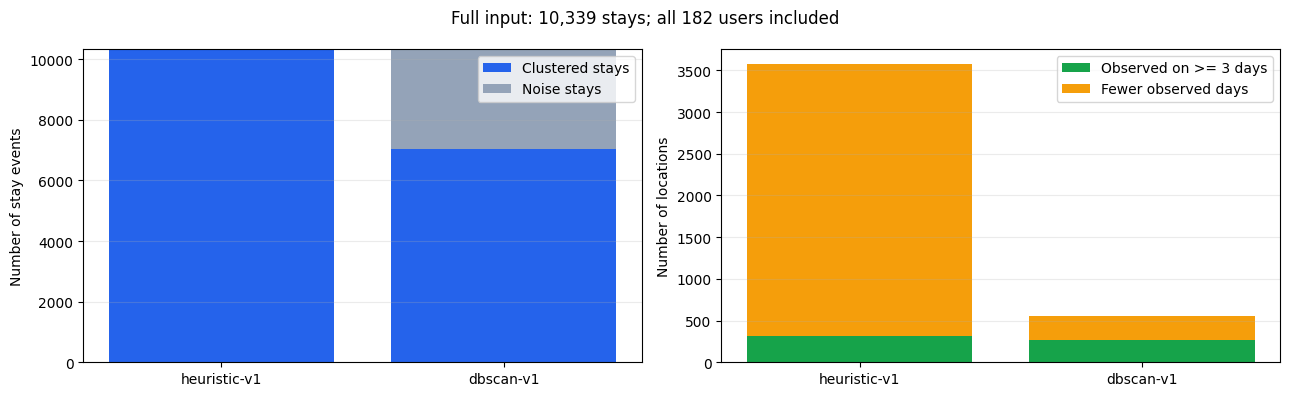

In [7]:
labels = comparison['method'].tolist()
x = np.arange(len(labels))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(x, comparison['clustered_stays'], label='Clustered stays', color='#2563eb')
axes[0].bar(x, comparison['noise_stays'], bottom=comparison['clustered_stays'], label='Noise stays', color='#94a3b8')
axes[1].bar(x, comparison['recurring_candidates'], label=f'Observed on >= {MIN_RECURRING_DAYS} days', color='#16a34a')
axes[1].bar(x, comparison['locations'] - comparison['recurring_candidates'],
            bottom=comparison['recurring_candidates'], label='Fewer observed days', color='#f59e0b')
for ax, ylabel in zip(axes, ['Number of stay events', 'Number of locations']):
    ax.set_xticks(x, labels)
    ax.set_ylabel(ylabel)
    ax.grid(axis='y', alpha=.25)
    ax.legend()
fig.suptitle(f'Full input: {len(stays):,} stays; all {len(users)} users included')
fig.tight_layout()
fig.savefig(OUT / '01_grouping_comparison.png', dpi=150)
plt.show()

## 7. Địa điểm được ghi nhận bao nhiêu ngày và phân tán rộng thế nào?

Hai đường ECDF dùng **mọi địa điểm của mỗi phương pháp**, mỗi địa điểm một trọng số; noise không có trong mẫu số.

- **Trái:** X là số ngày có dừng tại địa điểm; Y là tỷ lệ địa điểm có số ngày **≤ X**. Ví dụ Y = 0,8 tại X = 3 nghĩa là 80% địa điểm được ghi nhận không quá 3 ngày.
- **Phải:** X là khoảng cách xa nhất từ vị trí stay tới median cluster (m); Y là tỷ lệ địa điểm có khoảng cách xa nhất **≤ X**. Trục X nén theo log sau 1 m, vẫn hiển thị được giá trị 0. Đường đứng 100 m chỉ để đối chiếu eps, không phải ràng buộc bán kính cluster của DBSCAN.

Bảng cuối liệt kê 10 cluster rộng nhất **của mỗi phương pháp**, chỉ để xem phần đuôi; mọi phép tính và chart vẫn dùng toàn input. Cluster rộng có thể do chuỗi nối, jitter, hoặc gom nhiều nơi gần nhau; chưa thể xác định nguyên nhân chỉ bằng bảng này.

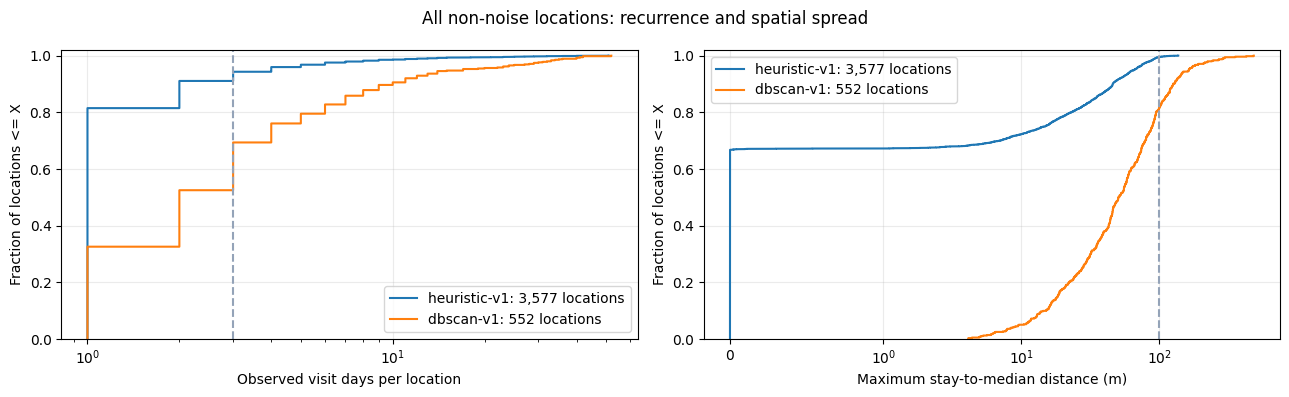

heuristic-v1 — 10 clusters rộng nhất:


,method,user_id,cluster_id,latitude,longitude,stay_event_count,visit_count,unique_visit_days,distinct_weeks,total_dwell_minutes,radius_max_m,radius_p95_m,recurring_candidate,extent_over_2eps
1191,heuristic-v1,038,14,39.968702,116.309088,32,32,12,6,568.450000,136.890139,75.065315,True,False
1010,heuristic-v1,032,3,39.973612,116.333878,22,22,6,3,384.666667,126.977860,69.053395,True,False
1101,heuristic-v1,036,9,39.980812,116.338720,10,10,8,6,189.183333,121.565696,101.486504,True,False
1817,heuristic-v1,068,15,39.996052,116.417321,26,26,18,13,443.383333,117.857259,99.810352,True,False
2121,heuristic-v1,092,26,40.030500,116.408698,25,25,6,2,379.216667,115.882714,74.873309,True,False
2025,heuristic-v1,085,2,39.981047,116.327530,26,26,14,11,554.383333,113.343987,87.648852,True,False
550,heuristic-v1,017,15,39.967156,116.409797,74,74,31,17,1230.100000,112.274903,72.241841,True,False
1324,heuristic-v1,041,1,39.859595,116.257588,34,34,28,17,514.300000,109.901574,50.571045,True,False
1193,heuristic-v1,038,16,39.968332,116.309207,27,27,14,8,465.900000,108.598034,53.333730,True,False
307,heuristic-v1,005,4,40.011514,116.321119,65,65,11,6,1247.200000,107.286738,60.608308,True,False


dbscan-v1 — 10 clusters rộng nhất:


,method,user_id,cluster_id,latitude,longitude,stay_event_count,visit_count,unique_visit_days,distinct_weeks,total_dwell_minutes,radius_max_m,radius_p95_m,recurring_candidate,extent_over_2eps
3813,dbscan-v1,036,4,39.977519,116.339173,83,83,23,10,1514.550000,482.192752,412.128897,True,True
3597,dbscan-v1,003,0,40.007646,116.319703,121,121,34,20,2526.150000,425.633392,327.015402,True,True
3619,dbscan-v1,004,0,40.007137,116.320553,27,27,13,11,424.800000,353.566489,325.492375,True,True
3832,dbscan-v1,038,2,39.968556,116.309167,110,110,29,10,1901.166667,296.744060,223.193477,True,True
3680,dbscan-v1,017,2,39.967112,116.409757,87,87,40,22,1435.950000,296.615340,149.722478,True,True
3681,dbscan-v1,017,3,40.017708,116.341457,64,64,31,22,1144.800000,288.030105,179.930523,True,True
3972,dbscan-v1,085,1,39.980918,116.329223,137,137,35,21,3159.383333,285.632254,192.172334,True,True
4082,dbscan-v1,153,5,39.987233,116.449231,83,83,30,20,1376.033333,268.449310,181.266236,True,True
3984,dbscan-v1,092,3,40.030489,116.408856,48,48,7,3,712.383333,267.394296,220.433705,True,True
3939,dbscan-v1,068,4,39.996303,116.417237,93,93,42,25,1616.733333,245.304141,137.364097,True,True


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for method in METHODS:
    frame = locations.loc[locations['method'].eq(method)]
    if frame.empty:
        continue
    for ax, column in zip(axes, ['unique_visit_days', 'radius_max_m']):
        values = np.sort(frame[column].to_numpy(dtype=float))
        ax.step(values, np.arange(1, len(values) + 1) / len(values), where='post', label=f'{method}: {len(values):,} locations')
axes[0].set(xlabel='Observed visit days per location', ylabel='Fraction of locations <= X')
axes[0].set_xscale('log')
axes[0].axvline(MIN_RECURRING_DAYS, color='#94a3b8', linestyle='--')
axes[1].set(xlabel='Maximum stay-to-median distance (m)', ylabel='Fraction of locations <= X')
axes[1].set_xscale('symlog', linthresh=1)
axes[1].axvline(CONFIG.eps_m, color='#94a3b8', linestyle='--')
for ax in axes:
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=.25)
    if not locations.empty:
        ax.legend()
fig.suptitle('All non-noise locations: recurrence and spatial spread')
fig.tight_layout()
fig.savefig(OUT / '02_location_diagnostics.png', dpi=150)
plt.show()
for method in METHODS:
    print(method, '— 10 clusters rộng nhất:')
    display(locations.loc[locations['method'].eq(method)].sort_values('radius_max_m', ascending=False).head(10))

## 7b. Xem trên bản đồ tương tác

Hai bản đồ đặt cạnh nhau: **ghép theo bán kính** bên trái, **DBSCAN** bên phải, cùng vùng nhìn để so sánh.

- Chọn **bất kỳ user nào** hoặc **Toàn bộ users**; mặc định mở user đầu có stay để dễ nhìn. Map chứa mọi stays/locations, không lấy mẫu.
- Chấm màu là một stay; chấm xám là noise; vòng đậm là vị trí median cluster. Bấm vào để xem thời gian dừng hoặc số stays, số đợt ghé, số ngày ghé của cluster.
- Bật **Độ rộng cluster** để xem vòng có bán kính bằng khoảng cách lớn nhất từ vị trí stay tới median. Vòng này không phải ranh giới thực tế hay vòng eps của DBSCAN.
- Nút **Zoom nơi thường ghé** phóng tới địa điểm có nhiều ngày ghé nhất (ưu tiên DBSCAN). Hai bản đồ mặc định đồng bộ zoom. Màu và cluster ID không biểu thị sự tương ứng giữa hai phương pháp.

Cần internet để tải thư viện và nền đường phố OpenStreetMap. User không có stay sẽ hiện thông báo rõ ràng, không tạo vị trí giả.

Chỉ xuất **một file** `artifacts/locations/03_location_map.html`, có thể mở riêng bằng trình duyệt. Nếu VS Code không hiện iframe, mở file HTML này. Cell chỉ vẽ từ assignments/locations hiện có, không chạy lại grouping.

In [ ]:
from html import escape
from IPython.display import HTML
from geolife_inference.maps import write_location_map

assert input_fingerprints() == INPUT_FINGERPRINTS, 'Input đã đổi; chạy lại từ phần 1.'
assert {'eps_m': CONFIG.eps_m, 'min_samples': CONFIG.min_samples,
        'timezone': CONFIG.timezone, 'min_recurring_days': MIN_RECURRING_DAYS} == run_audit['grouping_config']
MAP_PATH = write_location_map(assignments, locations, users.index,
                              OUT / '03_location_map.html', CONFIG)
print('Mở riêng bằng trình duyệt:', MAP_PATH)
display(HTML('<iframe title="GeoLife location maps" width="100%" height="850" '
             'style="border:0;border-radius:10px" srcdoc="'
             + escape(MAP_PATH.read_text(encoding='utf-8'), quote=True) + '"></iframe>'))

## 8. Lưu kết quả baseline

`stay_assignments.csv` giữ đủ mọi stay và cả noise. `locations.csv` chỉ chứa các cluster thật (`cluster_id >= 0`). Audit ghi đủ input, cấu hình, counts và phần đã chạy; chỉ dùng kết quả khi trạng thái là `completed`.

Đổi CONFIG thì chạy lại từ phần 3 để bảng, chart và output cùng một cấu hình. Không thay ngưỡng NB03 trong notebook này.

In [9]:
try:
    assert input_fingerprints() == INPUT_FINGERPRINTS, 'Input đã đổi; chạy lại từ phần 1.'
    expected_config = {'eps_m': CONFIG.eps_m, 'min_samples': CONFIG.min_samples,
                       'timezone': CONFIG.timezone, 'min_recurring_days': MIN_RECURRING_DAYS}
    assert expected_config == run_audit['grouping_config'], 'CONFIG đã đổi; chạy lại từ phần 3.'
    for name, table in [('stay_assignments.csv', assignments), ('locations.csv', locations),
                        ('comparison.csv', comparison), ('per_user.csv', per_user)]:
        partial = OUT / (name + '.partial')
        table.to_csv(partial, index=False)
        partial.replace(OUT / name)
    run_audit.update(status='completed', input_users=len(users), users_with_stays=stays['user_id'].nunique(),
                     input_stays=len(stays), input_stay_minutes=float(stays['duration_minutes'].sum()),
                     source_processed_users=source_audit['processed_users'],
                     source_processed_trajectories=source_audit['processed_trajectories'],
                     comparison=comparison.to_dict('records'))
    write_audit()
except Exception as error:
    run_audit.update(status='failed', error=str(error))
    write_audit()
    raise
print('Đã lưu baseline tại:', OUT)
print('Status:', run_audit['status'])

Đã lưu baseline tại: e:\QUY\Geolife-Trajectories\artifacts\locations
Status: completed


## 9. Thử độ nhạy DBSCAN — tùy chọn, vẫn dùng toàn bộ stays

Bật `RUN_SENSITIVITY = True` để đổi một yếu tố mỗi lần so với DBSCAN baseline: eps 50/200 m hoặc min_samples 2/5. Mọi cấu hình đều dùng cùng **toàn bộ stays của NB03**, không lấy mẫu.

Không ghi đè assignments/locations baseline. Lưu bảng tổng hợp riêng, kèm cấu hình và fingerprint input. So số địa điểm, tỷ lệ noise và độ phân tán; không chọn cấu hình chỉ vì noise thấp hoặc nhiều địa điểm.

In [ ]:
RUN_SENSITIVITY = True  # Nếu muốn chạy sensitivity, đổi thành True; nếu không, giữ False.
if RUN_SENSITIVITY:
    assert run_audit['status'] == 'completed'
    assert input_fingerprints() == INPUT_FINGERPRINTS, 'Input đã đổi; chạy lại từ phần 1.'
    assert {'eps_m': CONFIG.eps_m, 'min_samples': CONFIG.min_samples,
            'timezone': CONFIG.timezone, 'min_recurring_days': MIN_RECURRING_DAYS} == run_audit['grouping_config']
    scenarios = {'eps_50m': replace(CONFIG, eps_m=50), 'eps_200m': replace(CONFIG, eps_m=200),
                 'min_samples_2': replace(CONFIG, min_samples=2), 'min_samples_5': replace(CONFIG, min_samples=5)}
    baseline = comparison.loc[comparison['method'].eq('dbscan-v1')].iloc[0].to_dict()
    rows = [dict(scenario='baseline', eps_m=CONFIG.eps_m, min_samples=CONFIG.min_samples, **baseline)]
    for name, config in scenarios.items():
        print(name)
        grouped = group_locations(stays, config, 'dbscan-v1')
        places = summarize_locations(grouped, config, 'dbscan-v1')
        totals, _ = grouping_tables(grouped, places, 'dbscan-v1')
        rows.append(dict(scenario=name, eps_m=config.eps_m, min_samples=config.min_samples, **totals))
    assert input_fingerprints() == INPUT_FINGERPRINTS, 'Input đổi khi chạy sensitivity.'
    sensitivity = pd.DataFrame(rows)
    partial = OUT / 'sensitivity.csv.partial'
    sensitivity.to_csv(partial, index=False)
    partial.replace(OUT / 'sensitivity.csv')
    sensitivity_audit = {'status': 'completed', 'scope': 'full_dataset',
                         'input_fingerprints': INPUT_FINGERPRINTS,
                         'baseline_config': run_audit['grouping_config'],
                         'comparison': sensitivity.to_dict('records')}
    partial = OUT / 'sensitivity_audit.json.partial'
    partial.write_text(json.dumps(sensitivity_audit, ensure_ascii=False, indent=2), encoding='utf-8')
    partial.replace(OUT / 'sensitivity_audit.json')
    display(sensitivity)
else:
    print('Chưa chạy sensitivity. Các phần baseline đã dùng toàn bộ stays.')

Chưa chạy sensitivity. Các phần baseline đã dùng toàn bộ stays.


## Kết quả phase 4

`artifacts/locations/` chứa bốn CSV baseline, audit, hai chart và một bản đồ HTML tương tác; sensitivity chỉ có khi bật và chạy xong phần 9. Giữ một bản notebook trong `notebooks/`, không tạo notebook output thứ hai.

Đã chuyển từ **nhiều lần dừng → các địa điểm của từng user**, có số ngày ghé, số đợt ghé và độ phân tán. DBSCAN vẫn có thể nhận nhiều stays cùng ngày hoặc nối thành cluster quá rộng. Noise được giữ để review, không tự coi là điểm sai. Các ngưỡng còn là giả thuyết.

Phase 5 mới xem bằng chứng theo giờ đêm/giờ làm việc, so các ứng viên và quyết định Home/Office hoặc `unknown`. Notebook này chưa gán các nhãn đó, chưa đo accuracy vì không có nhãn độc lập.